In [3]:
import pandas as pd

df_fake = pd.read_csv('Fake.csv')
df_true = pd.read_csv('True.csv')

df_fake['label'] = 1
df_true['label'] = 0

df = pd.concat([df_fake, df_true], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.to_csv('news.csv', index=False)

print("news.csv file created successfully!")

news.csv file created successfully!


                                               title  \
0  Ben Stein Calls Out 9th Circuit Court: Committ...   
1  Trump drops Steve Bannon from National Securit...   
2  Puerto Rico expects U.S. to lift Jones Act shi...   
3   OOPS: Trump Just Accidentally Confirmed He Le...   
4  Donald Trump heads for Scotland to reopen a go...   

                                                text       subject  \
0  21st Century Wire says Ben Stein, reputable pr...       US_News   
1  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
3  On Monday, Donald Trump once again embarrassed...          News   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                  date  label  
0    February 13, 2017      1  
1       April 5, 2017       0  
2  September 27, 2017       0  
3         May 22, 2017      1  
4       June 24, 2016       0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 

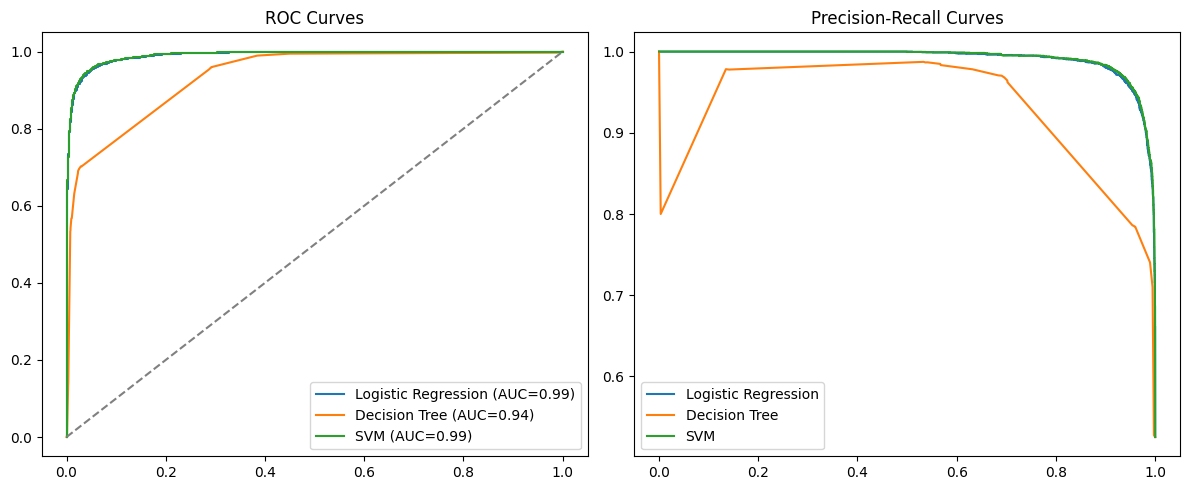

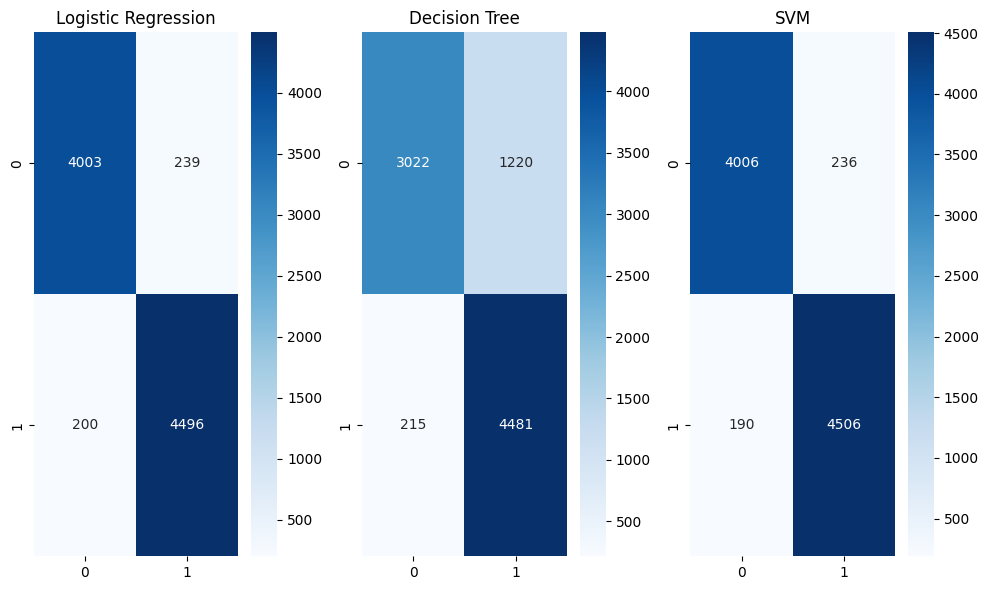

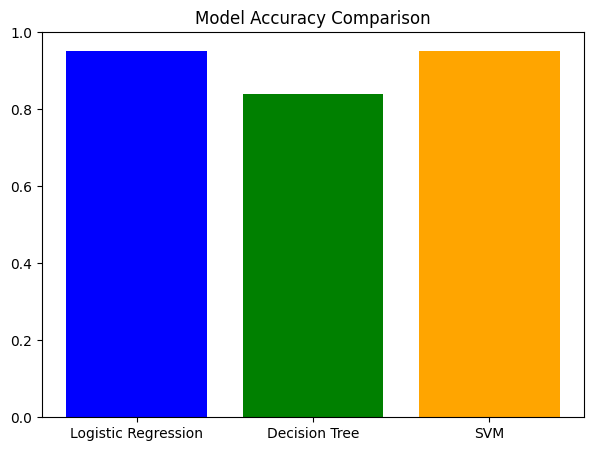

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

df = pd.read_csv('news.csv', engine='python', on_bad_lines='skip')

print(df.head())
print(df.info())

df = df.dropna().drop_duplicates()
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = " ".join([w for w in text.split() if len(w) > 4])
    return text

def add_noise(text):
    words = text.split()
    if len(words) > 10:
        words = np.random.choice(words, size=int(len(words)*0.5), replace=False)
    return " ".join(words)

df['title'] = df['title'].apply(clean_text)
df['text'] = df['text'].apply(clean_text)
df['text'] = df['text'].apply(add_noise)

X = df['title'] + " " + df['text']
y = df['label']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english', max_features=700)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

model_lr = LogisticRegression(max_iter=1000, C=0.5)
model_dt = DecisionTreeClassifier(max_depth=8, min_samples_split=10,
                                  min_samples_leaf=5, random_state=42)
model_svm = LinearSVC(C=0.1)

models = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "SVM": model_svm
}

for m in models.values():
    m.fit(X_train_vec, y_train)

from sklearn.metrics import classification_report, accuracy_score

accuracies = []

for name, model in models.items():
    y_pred = model.predict(X_test_vec)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

    print(f"\n{name} Accuracy: {acc}")
    print(classification_report(y_test, y_pred))

from sklearn.metrics import roc_curve, auc, precision_recall_curve

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
for name, model in models.items():
    if name in ["Logistic Regression", "Decision Tree"]:
        y_score = model.predict_proba(X_test_vec)[:, 1]
    else:
        y_score = model.decision_function(X_test_vec)

    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.2f})")

plt.plot([0,1],[0,1],'--', color='gray')
plt.title("ROC Curves")
plt.legend()

plt.subplot(1,2,2)
for name, model in models.items():
    if name in ["Logistic Regression", "Decision Tree"]:
        y_score = model.predict_proba(X_test_vec)[:, 1]
    else:
        y_score = model.decision_function(X_test_vec)

    precision, recall, _ = precision_recall_curve(y_test, y_score)
    plt.plot(recall, precision, label=name)

plt.title("Precision-Recall Curves")
plt.legend()
plt.tight_layout()
plt.show()

from sklearn.metrics import confusion_matrix

plt.figure(figsize=(10,6))

for i, (name, model) in enumerate(models.items(), 1):
    y_pred = model.predict(X_test_vec)
    cm = confusion_matrix(y_test, y_pred)

    plt.subplot(1,3,i)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(name)

plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.bar(models.keys(), accuracies, color=['blue','green','orange'])
plt.ylim(0,1)
plt.title("Model Accuracy Comparison")
plt.show()